In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
file_path = "../data/raw/PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(6362620, 11)


In [3]:
print("First 5 rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0



Column Names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Missing Values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


In [4]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [5]:
print("Fraud vs Legitimate:")
print(df["isFraud"].value_counts())

print("\nFraud Percentage:")
print(df["isFraud"].mean() * 100)

Fraud vs Legitimate:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud Percentage:
0.12908204481801522


In [6]:
fraud_by_type = df[df["isFraud"] == 1]["type"].value_counts()

print("Fraud Transactions by Type:")
print(fraud_by_type)

Fraud Transactions by Type:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


In [7]:
fraud_rate = df.groupby("type")["isFraud"].mean() * 100

print("Fraud Rate by Transaction Type:")
print(fraud_rate.sort_values(ascending=False))

Fraud Rate by Transaction Type:
type
TRANSFER    0.768799
CASH_OUT    0.183955
CASH_IN     0.000000
DEBIT       0.000000
PAYMENT     0.000000
Name: isFraud, dtype: float64


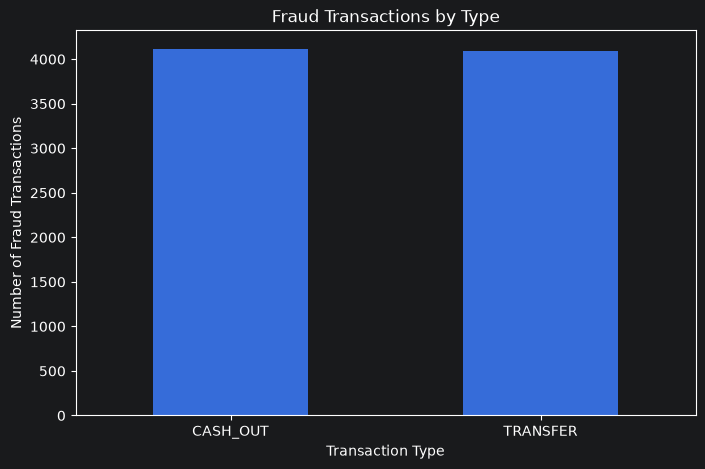

In [8]:
fraud_by_type.plot(kind="bar", figsize=(8, 5))

plt.title("Fraud Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(rotation=0)

plt.show()

In [9]:
print("Transaction Amount Statistics:")
print(df["amount"].describe())

Transaction Amount Statistics:
count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64


In [10]:
print("Average Transaction Amount:")

print("Legitimate:",
      df[df["isFraud"] == 0]["amount"].mean())

print("Fraud:",
      df[df["isFraud"] == 1]["amount"].mean())

print("\nMedian Transaction Amount:")

print("Legitimate:",
      df[df["isFraud"] == 0]["amount"].median())

print("Fraud:",
      df[df["isFraud"] == 1]["amount"].median())

Average Transaction Amount:
Legitimate: 178197.0417274075
Fraud: 1467967.2991403872

Median Transaction Amount:
Legitimate: 74684.72
Fraud: 441423.44


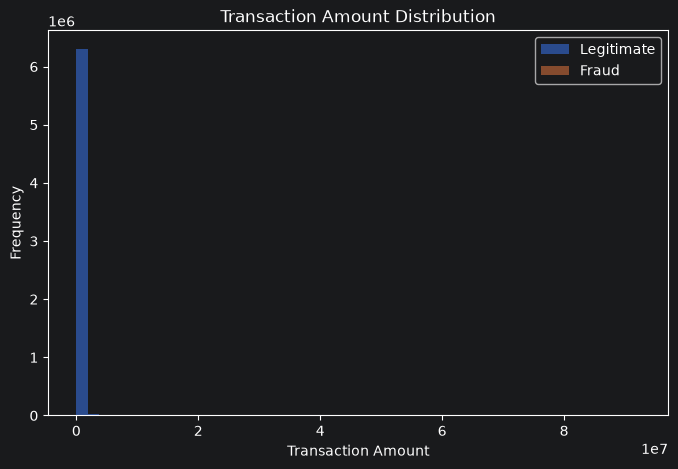

In [11]:
plt.figure(figsize=(8, 5))

df[df["isFraud"] == 0]["amount"].plot(
    kind="hist",
    bins=50,
    alpha=0.6,
    label="Legitimate"
)

df[df["isFraud"] == 1]["amount"].plot(
    kind="hist",
    bins=50,
    alpha=0.6,
    label="Fraud"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.legend()

plt.show()

In [12]:
print("Average Sender Balance Before Transaction:")

print("Legitimate:",
      df[df["isFraud"] == 0]["oldbalanceOrg"].mean())

print("Fraud:",
      df[df["isFraud"] == 1]["oldbalanceOrg"].mean())


print("\nAverage Sender Balance After Transaction:")

print("Legitimate:",
      df[df["isFraud"] == 0]["newbalanceOrig"].mean())

print("Fraud:",
      df[df["isFraud"] == 1]["newbalanceOrig"].mean())

Average Sender Balance Before Transaction:
Legitimate: 832828.7117272626
Fraud: 1649667.6057116764

Average Sender Balance After Transaction:
Legitimate: 855970.2281088117
Fraud: 192392.63183611346


In [13]:
print("Average Receiver Balance Before Transaction:")

print("Legitimate:",
      df[df["isFraud"] == 0]["oldbalanceDest"].mean())

print("Fraud:",
      df[df["isFraud"] == 1]["oldbalanceDest"].mean())


print("\nAverage Receiver Balance After Transaction:")

print("Legitimate:",
      df[df["isFraud"] == 0]["newbalanceDest"].mean())

print("Fraud:",
      df[df["isFraud"] == 1]["newbalanceDest"].mean())

Average Receiver Balance Before Transaction:
Legitimate: 1101420.8745693797
Fraud: 544249.6190746378

Average Receiver Balance After Transaction:
Legitimate: 1224925.6845631606
Fraud: 1279707.617145988


In [14]:
numeric_df = df.select_dtypes(include=["number"])

correlation = numeric_df.corr()["isFraud"].sort_values(ascending=False)

print("Correlation with Fraud:")
print(correlation)

Correlation with Fraud:
isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64
